<a href="https://colab.research.google.com/github/GarikapatiTejaswi/Telecom_Customer_Churn_Analysis/blob/main/Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [9]:
for col in df.columns:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


customerID
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
7398-LXGYX    1
1035-IPQPU    1
7203-OYKCT    1
1699-HPSBG    1
9837-FWLCH    1
Name: count, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

tenure
tenure
1     613
72    362
2     238
3     200
4     176
71    170
5     133
7     131
8     123
9     119
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No     

In [10]:
df['TotalCharges'].describe()

,TotalCharges
count,7043
unique,6531
top,
freq,11


In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [12]:
df['TotalCharges'].isnull()

,TotalCharges
0,False
1,False
2,False
3,False
4,False
...,...
7038,False
7039,False
7040,False
7041,False


In [13]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [14]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [15]:
df = df.drop("customerID", axis=1)

In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


In [18]:
df.shape

(7043, 20)

In [19]:
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [20]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [21]:
df.duplicated().sum()

np.int64(22)

In [22]:
df.to_csv("/content/customer_churn_cleaned.csv",
    index=False)

Exploratory Data Analysis

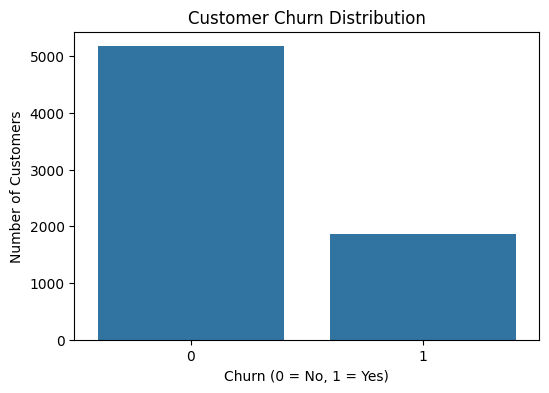

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [23]:
churn_counts = df["Churn"].value_counts()
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()
print(churn_counts)
print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

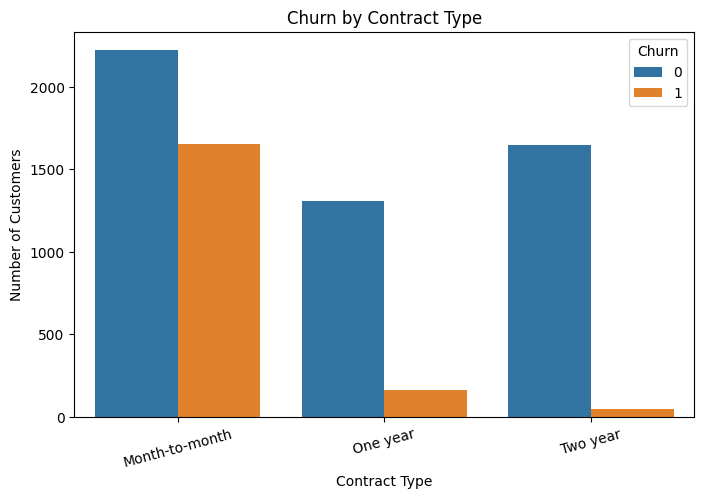

In [24]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

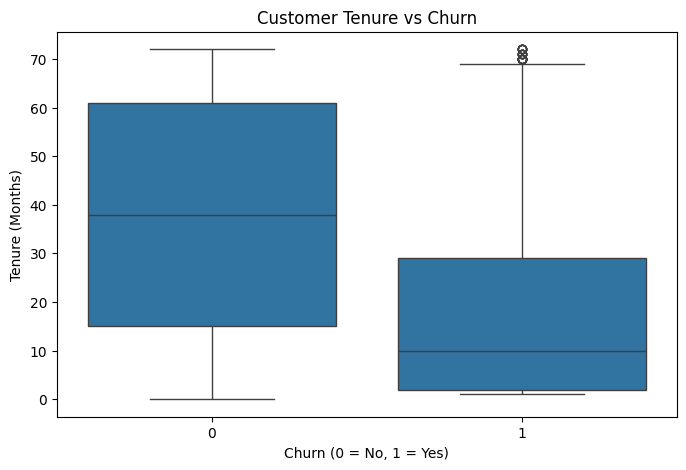

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")
plt.show()

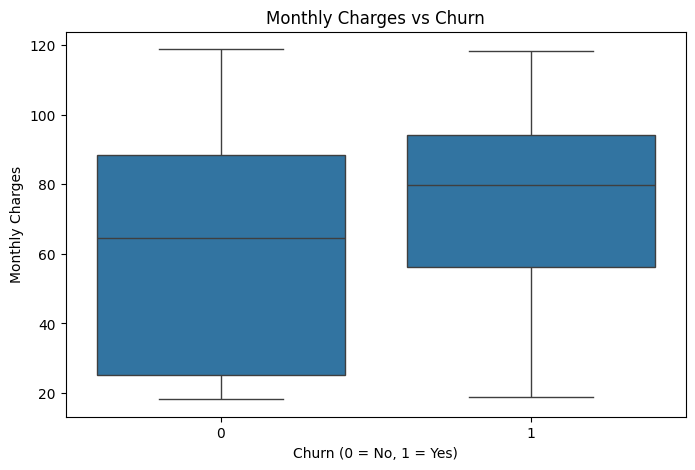

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")
plt.show()

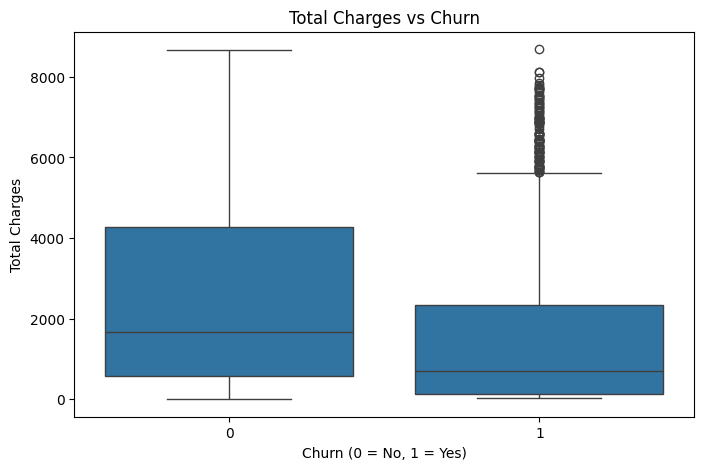

In [27]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Total Charges vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Total Charges")
plt.show()

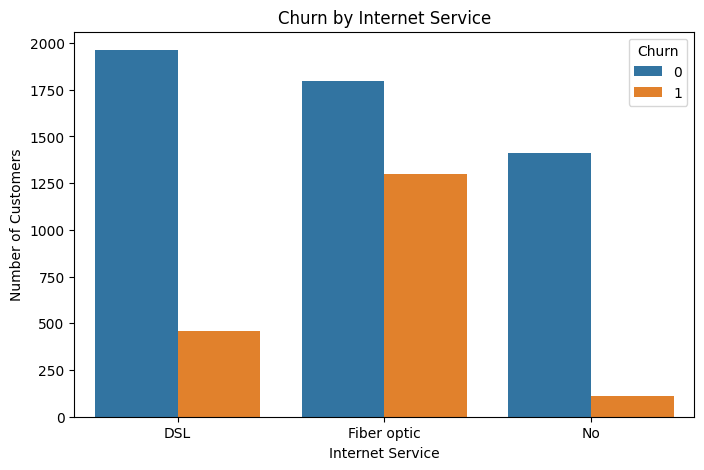

In [28]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

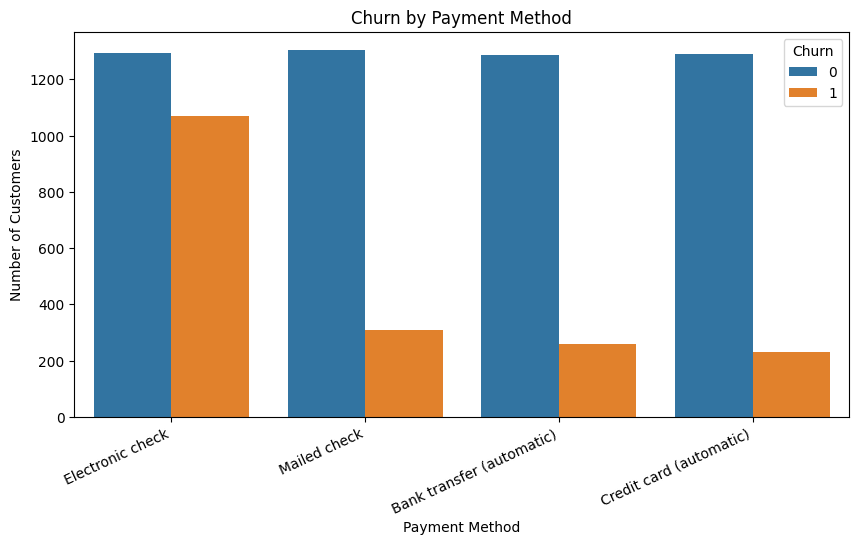

In [29]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.show()

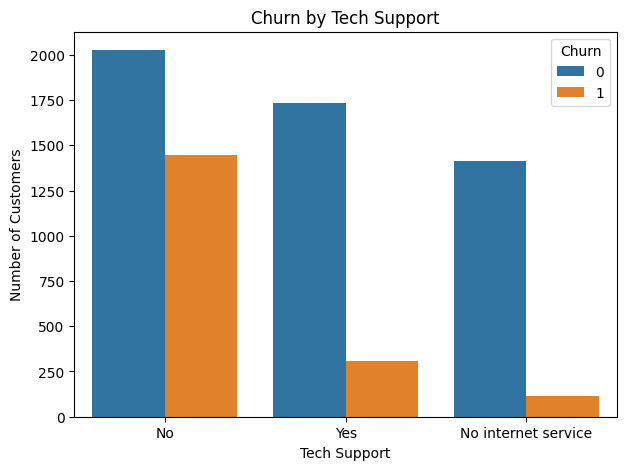

In [30]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="TechSupport", hue="Churn")
plt.title("Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")
plt.show()

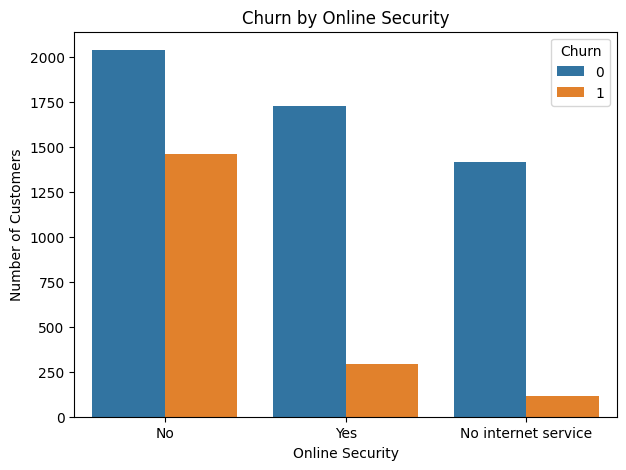

In [31]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="OnlineSecurity", hue="Churn")
plt.title("Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")
plt.show()

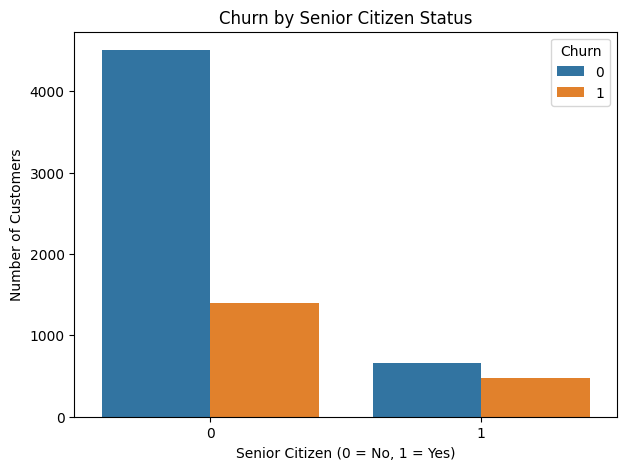

In [32]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="SeniorCitizen", hue="Churn")
plt.title("Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [33]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,0,1
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


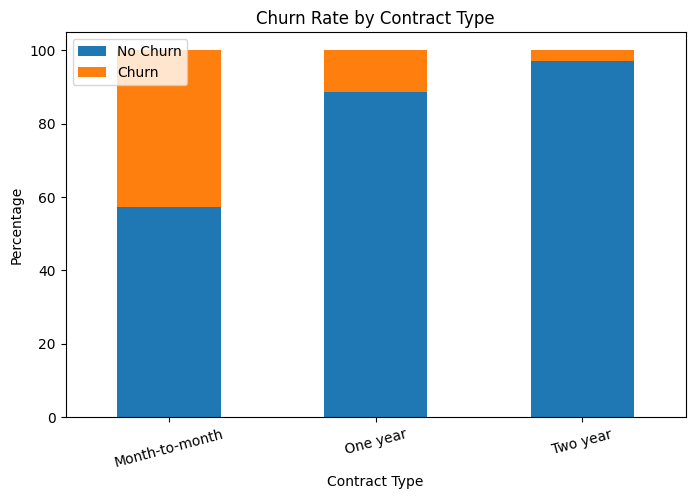

In [34]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")
plt.legend(["No Churn", "Churn"])
plt.xticks(rotation=15)
plt.show()

In [35]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [36]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn

Churn,0,1
TenureGroup,,
0-12 Months,52.321839,47.678161
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-72 Months,90.486824,9.513176


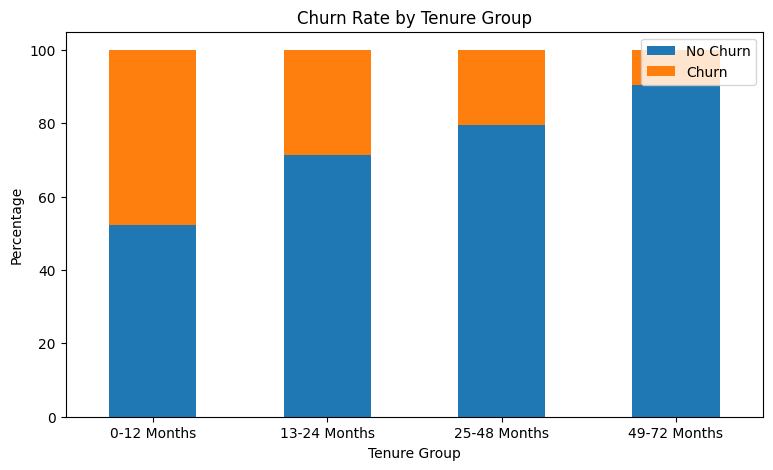

In [37]:
tenure_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["No Churn", "Churn"])
plt.show()

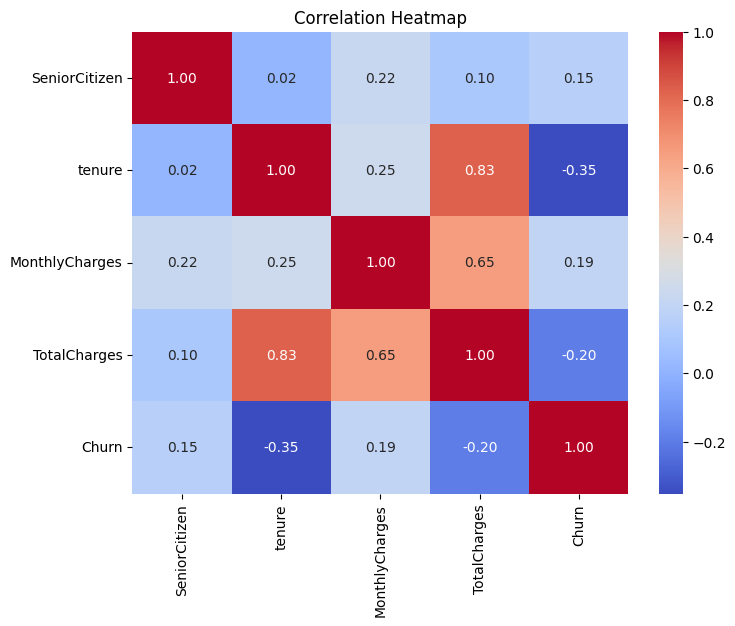

In [38]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [39]:
summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Non-Churned Customers",
        "Overall Churn Rate",
        "Average Tenure",
        "Average Monthly Charges",
        "Average Total Charges"
    ],
    "Value": [
        len(df),
        df["Churn"].sum(),
        (df["Churn"] == 0).sum(),
        df["Churn"].mean() * 100,
        df["tenure"].mean(),
        df["MonthlyCharges"].mean(),
        df["TotalCharges"].mean()
    ]
})

summary

,Metric,Value
0,Total Customers,7043.000000
1,Churned Customers,1869.000000
2,Non-Churned Customers,5174.000000
3,Overall Churn Rate,26.536987
4,Average Tenure,32.371149
5,Average Monthly Charges,64.761692
6,Average Total Charges,2279.734304


In [40]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup'],
      dtype='object')

In [41]:
df_ml = df.drop("TenureGroup", axis=1)

In [42]:
df_ml = df.copy()

if "TenureGroup" in df_ml.columns:
    df_ml = df_ml.drop("TenureGroup", axis=1)

In [43]:
X = df_ml.drop("Churn", axis=1)
y = df_ml["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [44]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [46]:
from sklearn.preprocessing import StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_cols
        )
    ]
)

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [48]:
print("Training Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Churn Distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [49]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [50]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [51]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.807
Precision: 0.6604
Recall   : 0.5615
F1 Score : 0.6069
ROC-AUC  : 0.8422


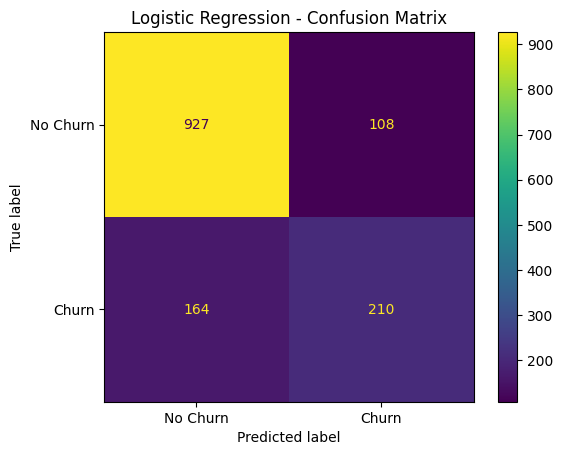

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [54]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

In [55]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [56]:
!pip install xgboost -q

In [57]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [58]:
def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

In [59]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred,
        y_prob
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred,
        dt_prob
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    )
)

results.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_pred,
        xgb_prob
    )
)

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8070,0.6604,0.5615,0.6069,0.8422
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267
2,Random Forest,0.7637,0.5412,0.7193,0.6177,0.8406
3,XGBoost,0.8055,0.6712,0.5241,0.5886,0.8425


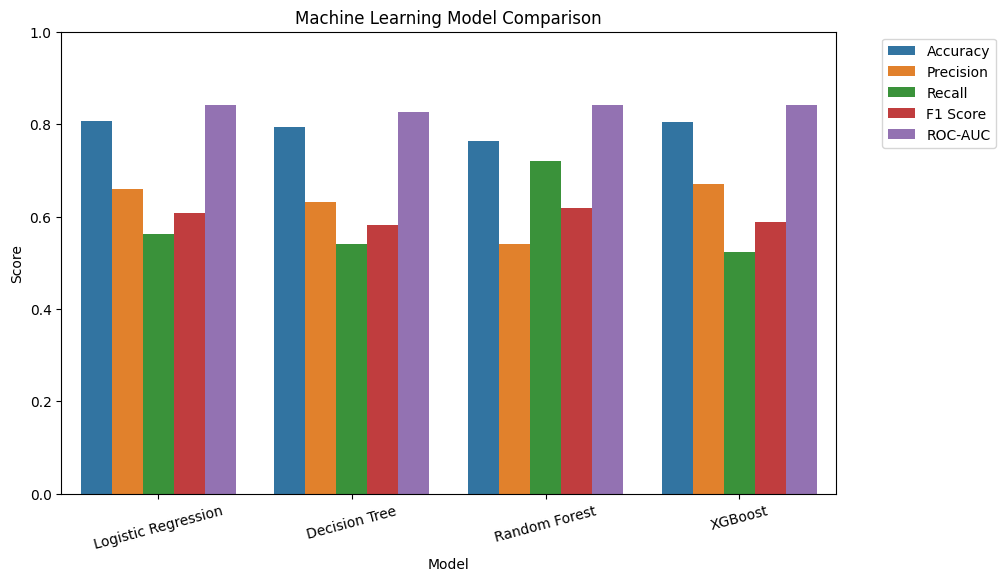

In [60]:
plt.figure(figsize=(10, 6))

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

In [61]:
best_model = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

print("Best Model:")
print(best_model)

Best Model:
Model         XGBoost
Accuracy     0.805536
Precision    0.671233
Recall       0.524064
F1 Score     0.588589
ROC-AUC       0.84254
Name: 3, dtype: object


In [62]:
best_recall = results_df.loc[
    results_df["Recall"].idxmax()
]

print("Best Recall Model:")
print(best_recall)

Best Recall Model:
Model        Random Forest
Accuracy          0.763662
Precision         0.541247
Recall            0.719251
F1 Score          0.617681
ROC-AUC           0.840563
Name: 2, dtype: object


In [63]:
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



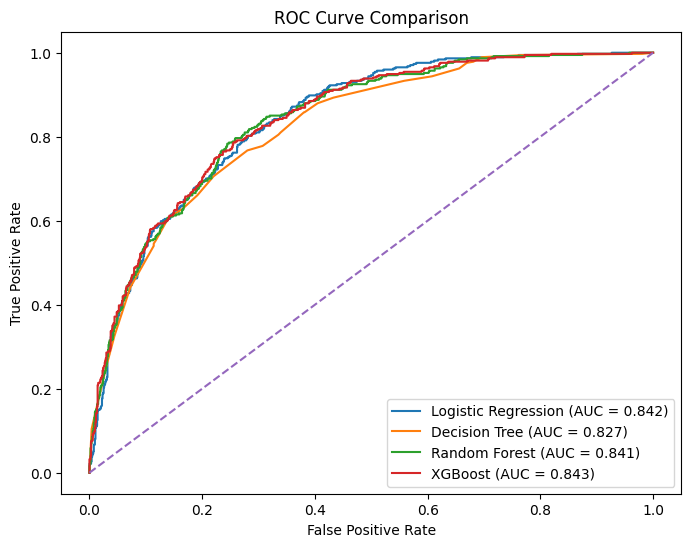

In [64]:
from sklearn.metrics import roc_curve

models_probabilities = {
    "Logistic Regression": y_prob,
    "Decision Tree": dt_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(8, 6))

for name, probabilities in models_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [65]:
# Select the model with the highest ROC-AUC
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(),
    "Model"
]

print("Selected Final Model:", best_model_name)

Selected Final Model: XGBoost


In [66]:
model_map = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

final_model = model_map[best_model_name]

print("Final model ready:", best_model_name)

Final model ready: XGBoost


In [67]:
all_predictions = final_model.predict(X)

all_probabilities = final_model.predict_proba(X)[:, 1]

In [68]:
predictions_df = df_ml.copy()

predictions_df["ChurnPrediction"] = all_predictions
predictions_df["ChurnProbability"] = all_probabilities

predictions_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnPrediction,ChurnProbability
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1,0.672023
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,0,0,0.020399
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,0.455683
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,0,0.028427
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,1,0.622326


In [69]:
def risk_category(probability):
    if probability >= 0.70:
        return "High Risk"
    elif probability >= 0.40:
        return "Medium Risk"
    else:
        return "Low Risk"

In [70]:
predictions_df["RiskCategory"] = (
    predictions_df["ChurnProbability"]
    .apply(risk_category)
)

In [71]:
predictions_df[
    [
        "ChurnPrediction",
        "ChurnProbability",
        "RiskCategory"
    ]
].head(10)

,ChurnPrediction,ChurnProbability,RiskCategory
0,1,0.672023,Medium Risk
1,0,0.020399,Low Risk
2,0,0.455683,Medium Risk
3,0,0.028427,Low Risk
4,1,0.622326,Medium Risk
5,1,0.919608,High Risk
6,0,0.396416,Low Risk
7,0,0.157255,Low Risk
8,1,0.646886,Medium Risk
9,0,0.013717,Low Risk


In [72]:
risk_counts = predictions_df["RiskCategory"].value_counts()

print(risk_counts)

RiskCategory
Low Risk       5025
Medium Risk    1369
High Risk       649
Name: count, dtype: int64


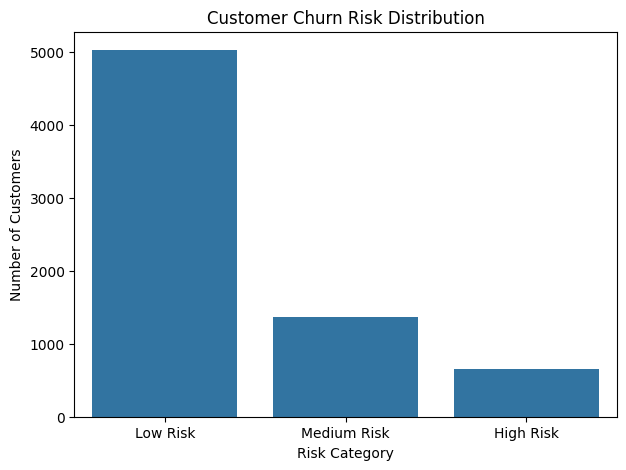

In [73]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=predictions_df,
    x="RiskCategory",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.show()

In [74]:
high_risk_customers = predictions_df[
    predictions_df["RiskCategory"] == "High Risk"
].copy()

print("High-risk customers:", len(high_risk_customers))

high_risk_customers.head(10)

High-risk customers: 649


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnPrediction,ChurnProbability,RiskCategory
5,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,1,0.919608,High Risk
20,Male,1,No,No,1,No,No phone service,DSL,No,No,...,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,1,1,0.898080,High Risk
31,Male,1,Yes,No,2,Yes,No,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),95.50,181.65,0,1,0.714442,High Risk
39,Female,0,No,No,11,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Bank transfer (automatic),97.85,1105.40,1,1,0.917727,High Risk
51,Female,0,No,No,15,Yes,No,Fiber optic,Yes,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.10,1426.40,1,1,0.707983,High Risk
53,Female,1,Yes,No,8,Yes,Yes,Fiber optic,No,Yes,...,No,Month-to-month,Yes,Credit card (automatic),80.65,633.30,1,1,0.758782,High Risk
64,Female,0,No,No,9,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,No,Electronic check,94.40,857.25,1,1,0.750854,High Risk
80,Female,0,No,Yes,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,79.35,79.35,1,1,0.915825,High Risk
85,Male,0,No,No,9,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),99.30,918.75,0,1,0.898464,High Risk
117,Female,0,Yes,Yes,10,Yes,Yes,Fiber optic,Yes,No,...,Yes,Month-to-month,Yes,Electronic check,100.25,1064.65,1,1,0.893271,High Risk


In [75]:
high_risk_customers = high_risk_customers.sort_values(
    "ChurnProbability",
    ascending=False
)

high_risk_customers.head(20)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnPrediction,ChurnProbability,RiskCategory
2208,Female,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.80,100.80,1,1,0.954994,High Risk
4800,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,94.00,94.00,1,1,0.949216,High Risk
1976,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,93.55,93.55,1,1,0.949192,High Risk
1704,Male,0,No,Yes,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.75,99.75,1,1,0.943889,High Risk
6482,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,101.45,101.45,1,1,0.941561,High Risk
3209,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,93.85,93.85,1,1,0.941293,High Risk
2577,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,94.60,94.60,1,1,0.940569,High Risk
4459,Female,0,No,No,1,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Credit card (automatic),100.25,100.25,1,1,0.939751,High Risk
4517,Female,1,Yes,No,11,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.55,1131.20,1,1,0.939472,High Risk
2464,Female,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,77.15,77.15,1,1,0.939093,High Risk


In [76]:
risk_report = predictions_df[
    [
        "tenure",
        "Contract",
        "InternetService",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges",
        "ChurnPrediction",
        "ChurnProbability",
        "RiskCategory"
    ]
].copy()

risk_report["ChurnProbability"] = (
    risk_report["ChurnProbability"] * 100
).round(2)

risk_report.head()

,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,TotalCharges,ChurnPrediction,ChurnProbability,RiskCategory
0,1,Month-to-month,DSL,Electronic check,29.85,29.85,1,67.199997,Medium Risk
1,34,One year,DSL,Mailed check,56.95,1889.50,0,2.040000,Low Risk
2,2,Month-to-month,DSL,Mailed check,53.85,108.15,0,45.570000,Medium Risk
3,45,One year,DSL,Bank transfer (automatic),42.30,1840.75,0,2.840000,Low Risk
4,2,Month-to-month,Fiber optic,Electronic check,70.70,151.65,1,62.230000,Medium Risk


In [77]:
risk_report = risk_report.rename(
    columns={
        "tenure": "TenureMonths",
        "Contract": "ContractType",
        "InternetService": "InternetServiceType",
        "MonthlyCharges": "MonthlyCharges",
        "TotalCharges": "TotalCharges",
        "ChurnPrediction": "PredictedChurn",
        "ChurnProbability": "ChurnProbabilityPercent"
    }
)

risk_report.head()

,TenureMonths,ContractType,InternetServiceType,PaymentMethod,MonthlyCharges,TotalCharges,PredictedChurn,ChurnProbabilityPercent,RiskCategory
0,1,Month-to-month,DSL,Electronic check,29.85,29.85,1,67.199997,Medium Risk
1,34,One year,DSL,Mailed check,56.95,1889.50,0,2.040000,Low Risk
2,2,Month-to-month,DSL,Mailed check,53.85,108.15,0,45.570000,Medium Risk
3,45,One year,DSL,Bank transfer (automatic),42.30,1840.75,0,2.840000,Low Risk
4,2,Month-to-month,Fiber optic,Electronic check,70.70,151.65,1,62.230000,Medium Risk


In [78]:
risk_report.to_csv(
    "/content/customer_churn_predictions.csv",
    index=False
)

print("Prediction file created successfully!")

Prediction file created successfully!


In [79]:
classifier = final_model.named_steps["classifier"]
preprocessor_fitted = final_model.named_steps["preprocessor"]

In [80]:
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

In [81]:
importances = classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
)

feature_importance_df.head(15)

,Feature,Importance
10,cat__InternetService_Fiber optic,0.266992
25,cat__Contract_Two year,0.153722
12,cat__OnlineSecurity_No internet service,0.082911
11,cat__InternetService_No,0.078131
24,cat__Contract_One year,0.053113
28,cat__PaymentMethod_Electronic check,0.046619
1,num__tenure,0.036293
14,cat__OnlineBackup_No internet service,0.031919
26,cat__PaperlessBilling_Yes,0.025317
23,cat__StreamingMovies_Yes,0.021818


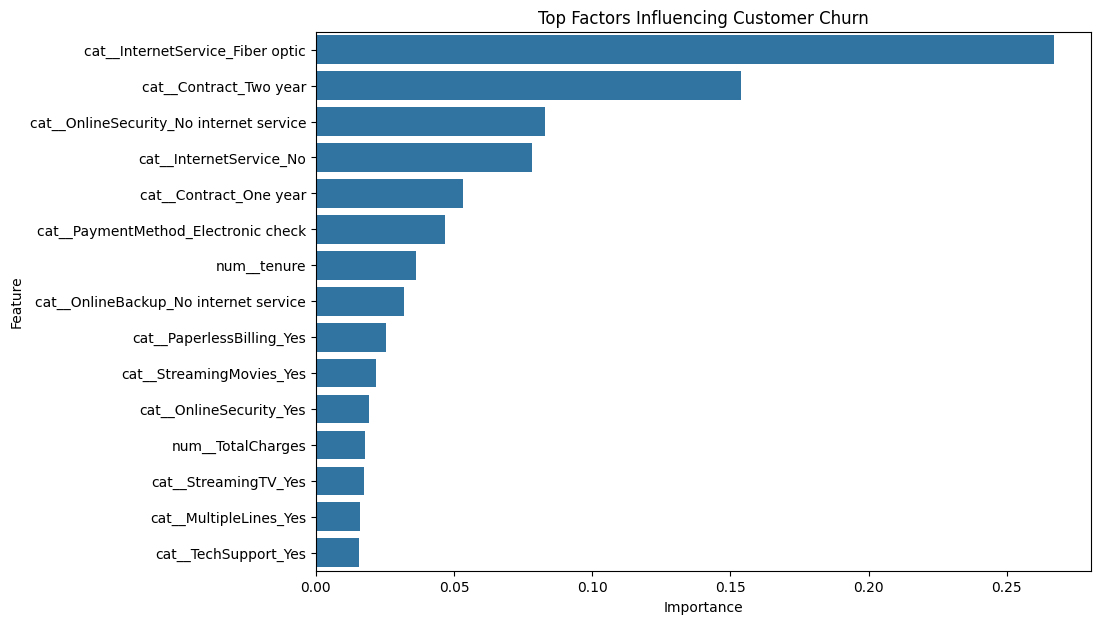

In [82]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top Factors Influencing Customer Churn")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [83]:
feature_importance_df

,Feature,Importance
10,cat__InternetService_Fiber optic,0.266992
25,cat__Contract_Two year,0.153722
12,cat__OnlineSecurity_No internet service,0.082911
11,cat__InternetService_No,0.078131
24,cat__Contract_One year,0.053113
28,cat__PaymentMethod_Electronic check,0.046619
1,num__tenure,0.036293
14,cat__OnlineBackup_No internet service,0.031919
26,cat__PaperlessBilling_Yes,0.025317
23,cat__StreamingMovies_Yes,0.021818


In [84]:
print("CUSTOMER CHURN PREDICTION SYSTEM")
print("======================================")

print("Final Model:", best_model_name)

print("\nModel Performance:")
print(results_df[
    results_df["Model"] == best_model_name
].round(4))

print("\nRisk Distribution:")
print(predictions_df["RiskCategory"].value_counts())

print("\nHigh-Risk Customers:",
      (predictions_df["RiskCategory"] == "High Risk").sum())

CUSTOMER CHURN PREDICTION SYSTEM
Final Model: XGBoost

Model Performance:
     Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
3  XGBoost    0.8055     0.6712  0.5241    0.5886   0.8425

Risk Distribution:
RiskCategory
Low Risk       5025
Medium Risk    1369
High Risk       649
Name: count, dtype: int64

High-Risk Customers: 649


In [85]:
risk_report["RevenueAtRisk"] = (
    risk_report["MonthlyCharges"] *
    risk_report["ChurnProbabilityPercent"] / 100
)

risk_report.to_csv(
    "/content/customer_churn_predictions.csv",
    index=False
)

print("Updated Tableau dataset saved!")

Updated Tableau dataset saved!


In [86]:
df.shape[0]

7043